In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
print("Library berhasil diimport!")

Library berhasil diimport!


# **Data Understanding**

In [2]:
df = pd.read_csv("/kaggle/input/datasets/samxsam/human-cognitive-performance-analysis/human_cognitive_performance.csv")
df.head()

,User_ID,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score
0,U1,57,Female,6.5,3,Non-Vegetarian,6.5,Medium,41,583.33,65,36.71,39.77
1,U2,39,Female,7.6,9,Non-Vegetarian,10.8,High,214,368.24,58,54.35,57.68
2,U3,26,Male,8.2,6,Vegetarian,5.7,Low,429,445.21,49,32.57,29.54
3,U4,32,Male,7.8,9,Vegetarian,8.3,Low,464,286.33,94,70.15,74.59
4,U5,50,Male,9.7,2,Non-Vegetarian,11.3,Medium,365,237.65,62,87.54,91.78


In [3]:
df.shape

(80000, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   User_ID             80000 non-null  object 
 1   Age                 80000 non-null  int64  
 2   Gender              80000 non-null  object 
 3   Sleep_Duration      80000 non-null  float64
 4   Stress_Level        80000 non-null  int64  
 5   Diet_Type           80000 non-null  object 
 6   Daily_Screen_Time   80000 non-null  float64
 7   Exercise_Frequency  80000 non-null  object 
 8   Caffeine_Intake     80000 non-null  int64  
 9   Reaction_Time       80000 non-null  float64
 10  Memory_Test_Score   80000 non-null  int64  
 11  Cognitive_Score     80000 non-null  float64
 12  AI_Predicted_Score  80000 non-null  float64
dtypes: float64(5), int64(4), object(4)
memory usage: 7.9+ MB


In [5]:
df.describe()

,Age,Sleep_Duration,Stress_Level,Daily_Screen_Time,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,AI_Predicted_Score
count,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000
mean,38.525525,7.005332,5.493762,6.504646,248.988213,399.973579,69.498350,58.172395,58.121357
std,12.101876,1.734435,2.865308,3.167072,144.541990,115.369329,17.305659,23.058522,23.119598
min,18.000000,4.000000,1.000000,1.000000,0.000000,200.000000,40.000000,0.000000,0.000000
25%,28.000000,5.500000,3.000000,3.800000,123.000000,300.150000,55.000000,40.910000,40.850000
50%,39.000000,7.000000,5.000000,6.500000,249.000000,400.360000,70.000000,58.360000,58.360000
75%,49.000000,8.500000,8.000000,9.200000,375.000000,499.250000,85.000000,75.830000,75.890000
max,59.000000,10.000000,10.000000,12.000000,499.000000,599.990000,99.000000,100.000000,100.000000


In [6]:
df.describe(include="object")

,User_ID,Gender,Diet_Type,Exercise_Frequency
count,80000,80000,80000,80000
unique,80000,3,3,3
top,U79961,Female,Non-Vegetarian,Medium
freq,1,38404,47986,31990


In [7]:
# Cek Missing Value

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

missing_summary

,Missing Values,Percentage (%)
User_ID,0,0.0
Age,0,0.0
Gender,0,0.0
Sleep_Duration,0,0.0
Stress_Level,0,0.0
Diet_Type,0,0.0
Daily_Screen_Time,0,0.0
Exercise_Frequency,0,0.0
Caffeine_Intake,0,0.0
Reaction_Time,0,0.0


In [8]:
# Cek Duplikat

duplicate_count = df.duplicated().sum()
duplicate_count

np.int64(0)

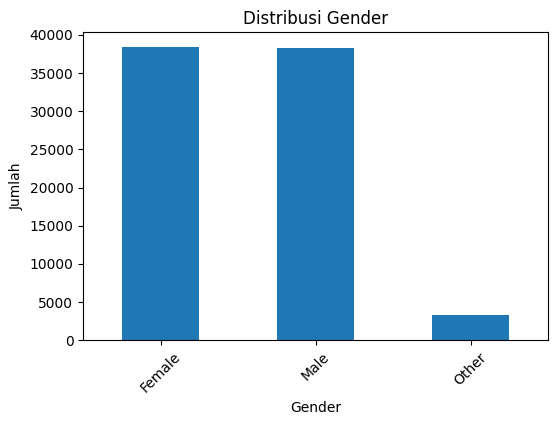

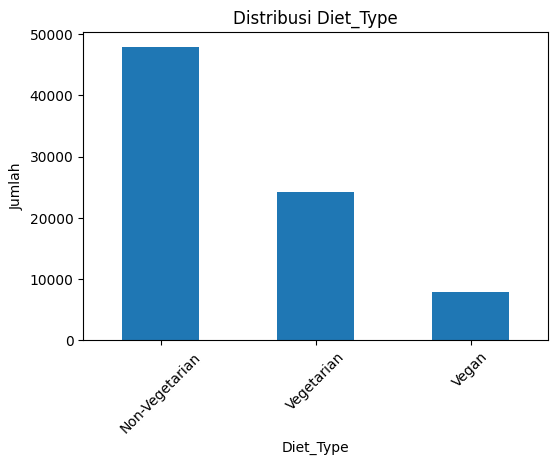

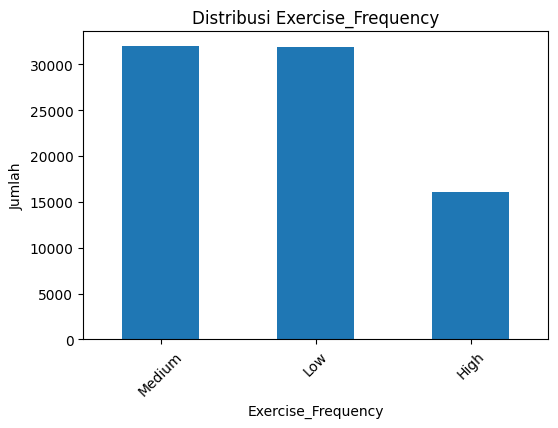

In [9]:
# Cek Kolom Kategorikal

categorical_cols = ["Gender", "Diet_Type", "Exercise_Frequency"]

for col in categorical_cols:
    plt.figure(figsize=(6,4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Jumlah")
    plt.xticks(rotation=45)
    plt.show()

In [10]:
# Cek Outlier

numeric_cols = df.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    outlier_summary.append({
        "Column": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,Column,Lower Bound,Upper Bound,Outlier Count
0,Age,-3.50,80.50,0
1,Sleep_Duration,1.00,13.00,0
2,Stress_Level,-4.50,15.50,0
3,Daily_Screen_Time,-4.30,17.30,0
4,Caffeine_Intake,-255.00,753.00,0
5,Reaction_Time,1.50,797.90,0
6,Memory_Test_Score,10.00,130.00,0
7,Cognitive_Score,-11.47,128.21,0
8,AI_Predicted_Score,-11.71,128.45,0


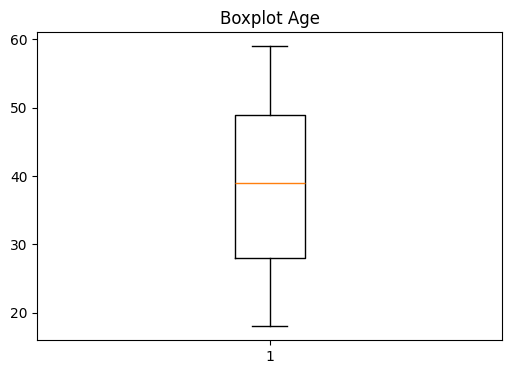

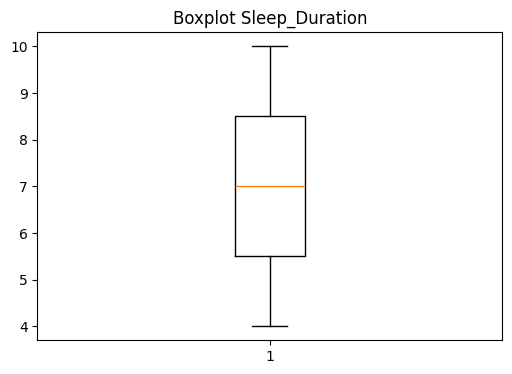

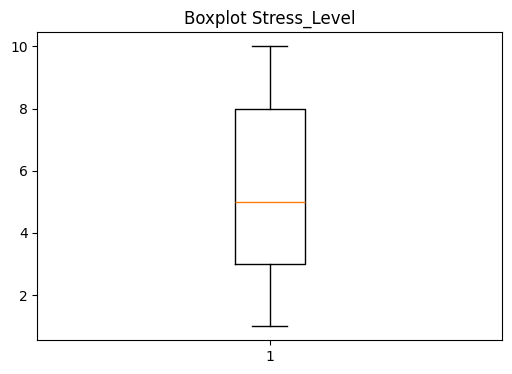

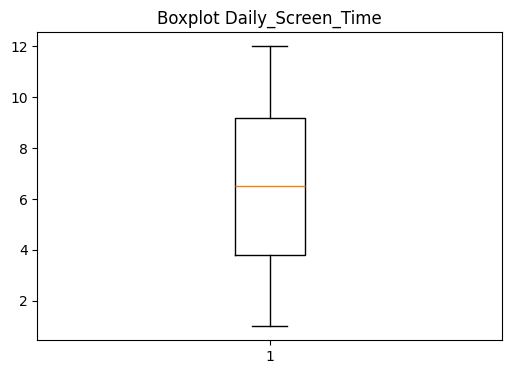

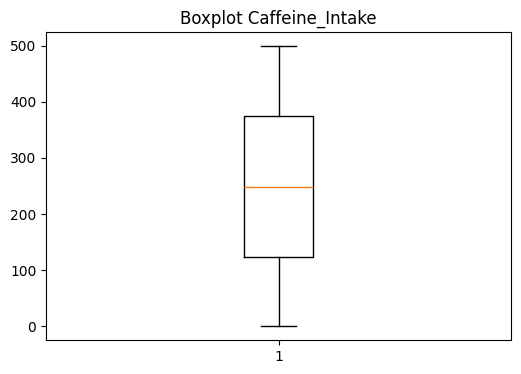

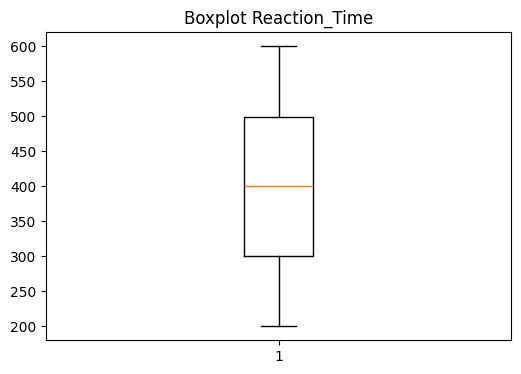

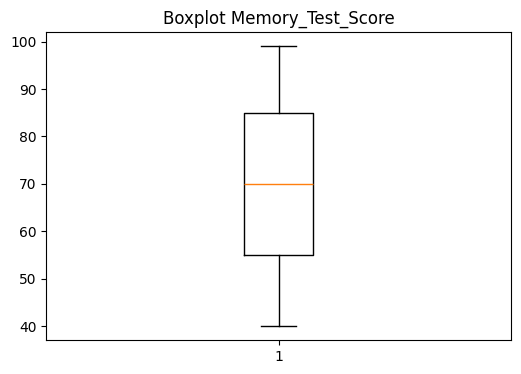

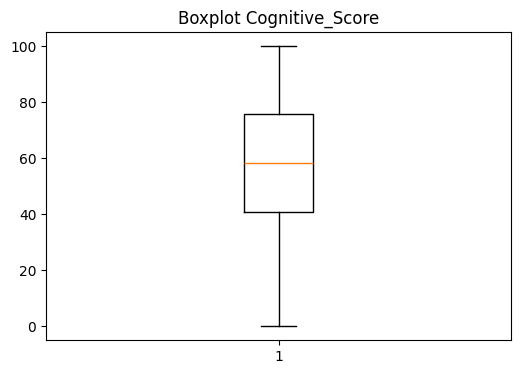

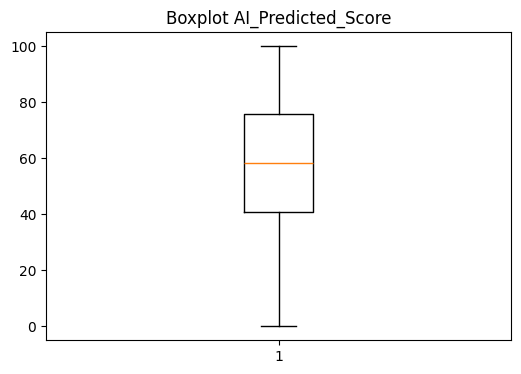

In [11]:
for col in numeric_cols:
    plt.figure(figsize=(6,4))
    plt.boxplot(df[col])
    plt.title(f"Boxplot {col}")
    plt.show()

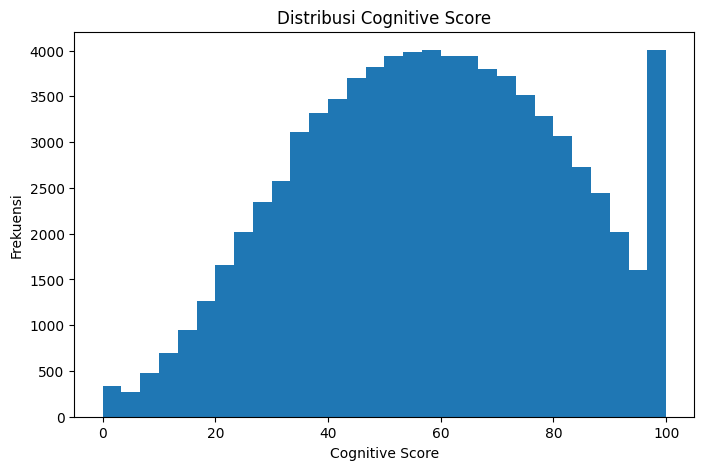

In [12]:
# Distribusi Fitur Target

plt.figure(figsize=(8, 5))
plt.hist(df["Cognitive_Score"], bins=30)
plt.title("Distribusi Cognitive Score")
plt.xlabel("Cognitive Score")
plt.ylabel("Frekuensi")
plt.show()

In [13]:
# Korelasi Numerik terhadap Fitur Target

correlation = df[numeric_cols].corr()["Cognitive_Score"].sort_values(ascending=False)
correlation

Cognitive_Score       1.000000
AI_Predicted_Score    0.992358
Memory_Test_Score     0.363894
Sleep_Duration        0.150595
Age                  -0.005976
Caffeine_Intake      -0.122862
Daily_Screen_Time    -0.198515
Stress_Level         -0.227639
Reaction_Time        -0.818470
Name: Cognitive_Score, dtype: float64

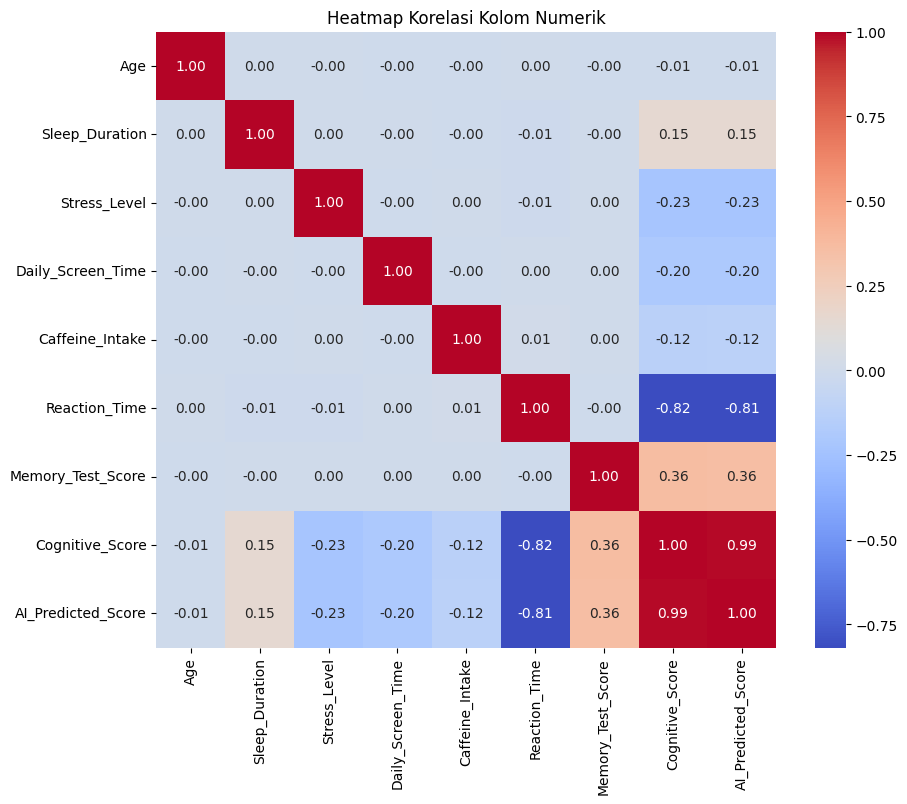

In [14]:
# Correlation Matrix

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Heatmap Korelasi Kolom Numerik")
plt.show()

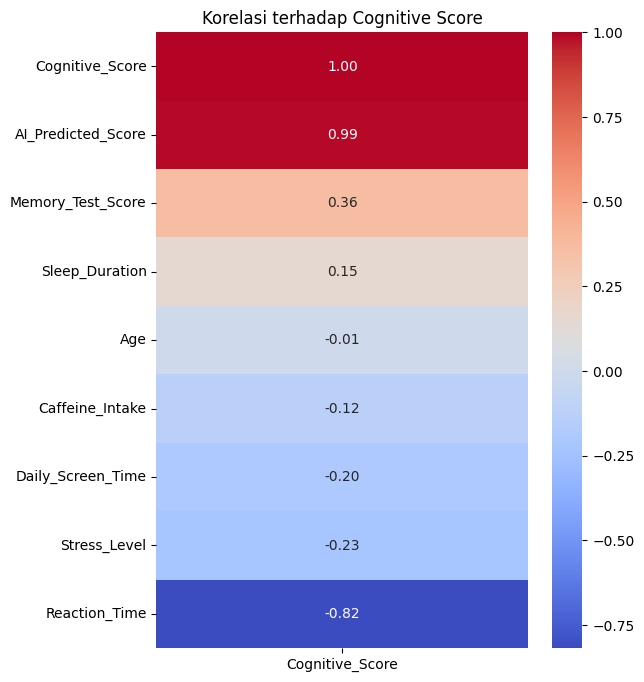

In [15]:
# Correlation Matrix terhadap Fitur Target

target_corr = numeric_df.corr()[["Cognitive_Score"]].sort_values(
    by="Cognitive_Score", 
    ascending=False
)

plt.figure(figsize=(6,8))
sns.heatmap(target_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi terhadap Cognitive Score")
plt.show()

# **Data Preparation**

In [16]:
df_model = df.copy()

df_model = df_model.drop(columns=["User_ID", "AI_Predicted_Score"])

df_model.head()

,Age,Gender,Sleep_Duration,Stress_Level,Diet_Type,Daily_Screen_Time,Exercise_Frequency,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score
0,57,Female,6.5,3,Non-Vegetarian,6.5,Medium,41,583.33,65,36.71
1,39,Female,7.6,9,Non-Vegetarian,10.8,High,214,368.24,58,54.35
2,26,Male,8.2,6,Vegetarian,5.7,Low,429,445.21,49,32.57
3,32,Male,7.8,9,Vegetarian,8.3,Low,464,286.33,94,70.15
4,50,Male,9.7,2,Non-Vegetarian,11.3,Medium,365,237.65,62,87.54


In [17]:
# Encoding Fitur Kategorikal

df_model = pd.get_dummies(
    df_model,
    columns=["Gender", "Diet_Type", "Exercise_Frequency"],
    drop_first=True
)

df_model.head()

,Age,Sleep_Duration,Stress_Level,Daily_Screen_Time,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,Gender_Male,Gender_Other,Diet_Type_Vegan,Diet_Type_Vegetarian,Exercise_Frequency_Low,Exercise_Frequency_Medium
0,57,6.5,3,6.5,41,583.33,65,36.71,False,False,False,False,False,True
1,39,7.6,9,10.8,214,368.24,58,54.35,False,False,False,False,False,False
2,26,8.2,6,5.7,429,445.21,49,32.57,True,False,False,True,True,False
3,32,7.8,9,8.3,464,286.33,94,70.15,True,False,False,True,True,False
4,50,9.7,2,11.3,365,237.65,62,87.54,True,False,False,False,False,True


In [18]:
bool_cols = df_model.select_dtypes(include="bool").columns
df_model[bool_cols] = df_model[bool_cols].astype(int)

df_model.head()

,Age,Sleep_Duration,Stress_Level,Daily_Screen_Time,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Cognitive_Score,Gender_Male,Gender_Other,Diet_Type_Vegan,Diet_Type_Vegetarian,Exercise_Frequency_Low,Exercise_Frequency_Medium
0,57,6.5,3,6.5,41,583.33,65,36.71,0,0,0,0,0,1
1,39,7.6,9,10.8,214,368.24,58,54.35,0,0,0,0,0,0
2,26,8.2,6,5.7,429,445.21,49,32.57,1,0,0,1,1,0
3,32,7.8,9,8.3,464,286.33,94,70.15,1,0,0,1,1,0
4,50,9.7,2,11.3,365,237.65,62,87.54,1,0,0,0,0,1


In [19]:
# Pisahkan Fitur dan Target

X = df_model.drop(columns=["Cognitive_Score"])
y = df_model["Cognitive_Score"]

In [20]:
X.head()

,Age,Sleep_Duration,Stress_Level,Daily_Screen_Time,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Gender_Male,Gender_Other,Diet_Type_Vegan,Diet_Type_Vegetarian,Exercise_Frequency_Low,Exercise_Frequency_Medium
0,57,6.5,3,6.5,41,583.33,65,0,0,0,0,0,1
1,39,7.6,9,10.8,214,368.24,58,0,0,0,0,0,0
2,26,8.2,6,5.7,429,445.21,49,1,0,0,1,1,0
3,32,7.8,9,8.3,464,286.33,94,1,0,0,1,1,0
4,50,9.7,2,11.3,365,237.65,62,1,0,0,0,0,1


In [21]:
y.head()

0    36.71
1    54.35
2    32.57
3    70.15
4    87.54
Name: Cognitive_Score, dtype: float64

In [22]:
# Train Test Split

np.random.seed(42)

indices = np.arange(len(df_model))
np.random.shuffle(indices)

test_size = 0.2
test_count = int(len(df_model) * test_size)

test_indices = indices[:test_count]
train_indices = indices[test_count:]

X_train = X.iloc[train_indices].values
X_test = X.iloc[test_indices].values

y_train = y.iloc[train_indices].values
y_test = y.iloc[test_indices].values

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (64000, 13)
X_test: (16000, 13)
y_train: (64000,)
y_test: (16000,)


In [23]:
# Scaling

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

In [24]:
print(X_train_scaled.dtype)

float64


In [25]:
X_train_scaled

array([[ 0.28545821,  1.55007759, -0.87044982, ...,  1.52276509,
        -0.81333738,  1.22494423],
       [ 0.863557  , -1.4445546 , -0.52160491, ..., -0.65670011,
        -0.81333738, -0.81636369],
       [-0.9533249 , -1.32937644,  1.57146458, ..., -0.65670011,
        -0.81333738,  1.22494423],
       ...,
       [ 1.2764847 ,  0.28311782, -0.87044982, ...,  1.52276509,
         1.22950208, -0.81636369],
       [ 0.69838592,  0.6286523 ,  0.87377475, ..., -0.65670011,
        -0.81333738,  1.22494423],
       [-0.12746949,  1.08936495, -1.21929473, ..., -0.65670011,
        -0.81333738,  1.22494423]])

In [26]:
X_test_scaled

array([[-1.28366706, -0.12000575, -1.21929473, ..., -0.65670011,
        -0.81333738,  1.22494423],
       [-1.28366706,  1.03177587,  1.22261966, ..., -0.65670011,
        -0.81333738, -0.81636369],
       [-1.11849598,  0.68624138, -0.52160491, ..., -0.65670011,
         1.22950208, -0.81636369],
       ...,
       [ 0.36804375, -0.98384196, -1.56813965, ..., -0.65670011,
        -0.81333738, -0.81636369],
       [ 1.11131362,  1.20454311, -1.21929473, ..., -0.65670011,
         1.22950208, -0.81636369],
       [-1.69659477, -1.4445546 , -0.17275999, ..., -0.65670011,
        -0.81333738, -0.81636369]])

# **Modeling**

**DESICION TREE REGRESSOR**

In [27]:
# Struktur Tree Node

class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature        # index fitur
        self.threshold = threshold    # nilai split
        self.left = left
        self.right = right
        self.value = value            # kalau leaf → isi nilai prediksi

In [28]:
# Fungsi MSE (Mean Squared Error)

def mse(y):
    if len(y) == 0:
        return 0
    return np.mean((y - np.mean(y)) ** 2)

In [29]:
# Cari Best Split

def best_split(X, y):
    best_feature = None
    best_threshold = None
    best_score = float("inf")
    
    n_samples, n_features = X.shape
    
    for feature in range(n_features):
        thresholds = np.unique(X[:, feature])
        
        for threshold in thresholds:
            
            left_mask = X[:, feature] <= threshold
            right_mask = X[:, feature] > threshold
            
            y_left = y[left_mask]
            y_right = y[right_mask]
            
            if len(y_left) == 0 or len(y_right) == 0:
                continue
            
            # weighted MSE
            score = (
                len(y_left)/n_samples * mse(y_left) +
                len(y_right)/n_samples * mse(y_right)
            )
            
            if score < best_score:
                best_score = score
                best_feature = feature
                best_threshold = threshold
                
    return best_feature, best_threshold

In [30]:
# Build Tree (Recursive)

def build_tree(X, y, depth=0, max_depth=5, min_samples_split=2):
    
    # stopping condition
    if len(y) < min_samples_split or depth >= max_depth:
        return Node(value=np.mean(y))
    
    feature, threshold = best_split(X, y)
    
    if feature is None:
        return Node(value=np.mean(y))
    
    left_mask = X[:, feature] <= threshold
    right_mask = X[:, feature] > threshold
    
    left = build_tree(X[left_mask], y[left_mask], depth+1, max_depth, min_samples_split)
    right = build_tree(X[right_mask], y[right_mask], depth+1, max_depth, min_samples_split)
    
    return Node(feature, threshold, left, right)

In [31]:
# Predict Sample Data

def predict_one(node, x):
    if node.value is not None:
        return node.value
    
    if x[node.feature] <= node.threshold:
        return predict_one(node.left, x)
    else:
        return predict_one(node.right, x)

In [32]:
# Predict Semua Data

def predict(tree, X):
    return np.array([predict_one(tree, x) for x in X])

In [33]:
# Train Model

tree = build_tree(X_train_scaled, y_train, max_depth=5)

In [34]:
# Prediksi

y_pred = predict(tree, X_test_scaled)

In [35]:
# MSE

mse_value = np.mean((y_test - y_pred) ** 2)
print("MSE:", mse_value)

MSE: 90.55737649553863


In [36]:
# RMSE

rmse = np.sqrt(mse_value)
print("RMSE:", rmse)

RMSE: 9.516163959050864


In [37]:
# R^2

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)
print("R2:", r2)

R2: 0.8281706126178501


In [38]:
def calculate_mse(y):
    if len(y) == 0:
        return 0
    return np.mean((y - np.mean(y)) ** 2)

In [39]:
class DecisionTreeRegressorManual:
    def __init__(self, max_depth=5, min_samples_split=5, max_features=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.root = None

    def fit(self, X, y):
        self.n_features = X.shape[1]

        if self.max_features is None:
            self.max_features = self.n_features

        self.root = self._build_tree(X, y, depth=0)

    def _best_split(self, X, y):
        best_feature = None
        best_threshold = None
        best_score = float("inf")

        n_samples, n_features = X.shape

        feature_indices = np.random.choice(
            n_features,
            self.max_features,
            replace=False
        )

        for feature in feature_indices:
            thresholds = np.unique(X[:, feature])

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = X[:, feature] > threshold

                y_left = y[left_mask]
                y_right = y[right_mask]

                if len(y_left) == 0 or len(y_right) == 0:
                    continue

                score = (
                    len(y_left) / n_samples * calculate_mse(y_left)
                    + len(y_right) / n_samples * calculate_mse(y_right)
                )

                if score < best_score:
                    best_score = score
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold

    def _build_tree(self, X, y, depth):
        if (
            depth >= self.max_depth
            or len(y) < self.min_samples_split
            or len(np.unique(y)) == 1
        ):
            return Node(value=np.mean(y))

        feature, threshold = self._best_split(X, y)

        if feature is None:
            return Node(value=np.mean(y))

        left_mask = X[:, feature] <= threshold
        right_mask = X[:, feature] > threshold

        left_child = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(
            feature=feature,
            threshold=threshold,
            left=left_child,
            right=right_child
        )

    def _predict_one(self, x, node):
        if node.value is not None:
            return node.value

        if x[node.feature] <= node.threshold:
            return self._predict_one(x, node.left)
        else:
            return self._predict_one(x, node.right)

    def predict(self, X):
        return np.array([self._predict_one(x, self.root) for x in X])

# **RANDOM FOREST REGRESSOR**

In [40]:
class RandomForestRegressorManual:
    def __init__(
        self,
        n_trees=10,
        max_depth=6,
        min_samples_split=5,
        max_features="sqrt",
        random_state=42
    ):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.random_state = random_state
        self.trees = []

    def _get_max_features(self, n_features):
        if self.max_features == "sqrt":
            return int(np.sqrt(n_features))
        elif self.max_features == "log2":
            return int(np.log2(n_features))
        elif isinstance(self.max_features, int):
            return self.max_features
        else:
            return n_features

    def _bootstrap_sample(self, X, y):
        n_samples = X.shape[0]
        indices = np.random.choice(n_samples, size=n_samples, replace=True)

        return X[indices], y[indices]

    def fit(self, X, y):
        np.random.seed(self.random_state)

        self.trees = []
        n_features = X.shape[1]
        max_features = self._get_max_features(n_features)

        for i in range(self.n_trees):
            X_sample, y_sample = self._bootstrap_sample(X, y)

            tree = DecisionTreeRegressorManual(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                max_features=max_features
            )

            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

            print(f"Tree {i+1}/{self.n_trees} selesai dilatih")

    def predict(self, X):
        tree_predictions = np.array([tree.predict(X) for tree in self.trees])

        return np.mean(tree_predictions, axis=0)

In [41]:
# Training Random Forest Regressor Model

rf_model = RandomForestRegressorManual(
    n_trees=10,
    max_depth=6,
    min_samples_split=10,
    max_features="sqrt",
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

Tree 1/10 selesai dilatih
Tree 2/10 selesai dilatih
Tree 3/10 selesai dilatih
Tree 4/10 selesai dilatih
Tree 5/10 selesai dilatih
Tree 6/10 selesai dilatih
Tree 7/10 selesai dilatih
Tree 8/10 selesai dilatih
Tree 9/10 selesai dilatih
Tree 10/10 selesai dilatih


In [42]:
# Prediksi

y_pred_rf = rf_model.predict(X_test_scaled)

# **Evaluasi**

In [43]:
# Metrik Evaluasi

mse_rf = np.mean((y_test - y_pred_rf) ** 2)
rmse_rf = np.sqrt(mse_rf)
mae_rf = np.mean(np.abs(y_test - y_pred_rf))

ss_res = np.sum((y_test - y_pred_rf) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2_rf = 1 - (ss_res / ss_tot)

print("Random Forest Regressor Manual")
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("MAE :", mae_rf)
print("R2  :", r2_rf)

Random Forest Regressor Manual
MSE : 100.22556697934732
RMSE: 10.011271996072592
MAE : 8.133484927763055
R2  : 0.8098255665021576


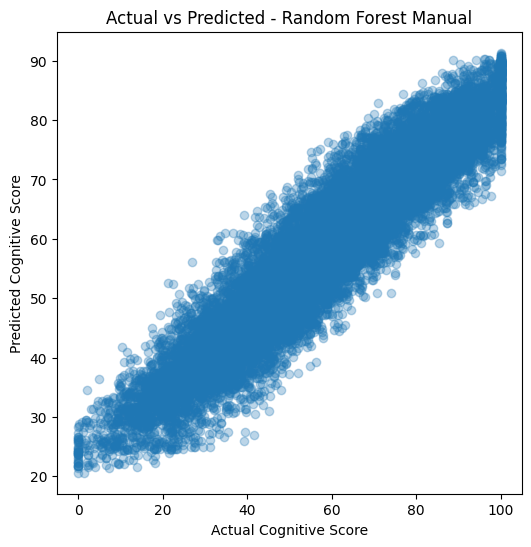

In [44]:
# Visualisasi Actual vs Predicted

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.xlabel("Actual Cognitive Score")
plt.ylabel("Predicted Cognitive Score")
plt.title("Actual vs Predicted - Random Forest Manual")
plt.show()

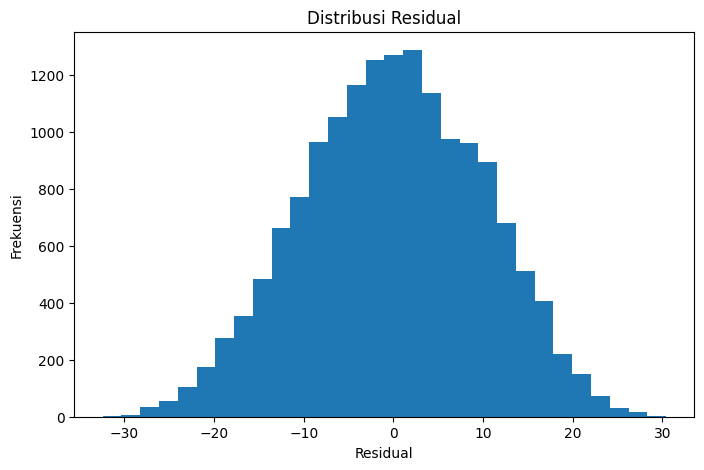

In [45]:
# Visualisasi Error

residuals = y_test - y_pred_rf

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30)
plt.xlabel("Residual")
plt.ylabel("Frekuensi")
plt.title("Distribusi Residual")
plt.show()

# **Hyperparameter Tuning**

In [46]:
# Setup Parameter Grid

param_grid = {
    "n_trees": [5, 10, 20],
    "max_depth": [4, 6, 8],
    "min_samples_split": [5, 10],
    "max_features": ["sqrt", "log2"]
}

In [47]:
# Loop Tuning

results = []

for n_trees in param_grid["n_trees"]:
    for max_depth in param_grid["max_depth"]:
        for min_samples_split in param_grid["min_samples_split"]:
            for max_features in param_grid["max_features"]:
                
                print(f"Testing: trees={n_trees}, depth={max_depth}, min_split={min_samples_split}, features={max_features}")
                
                model = RandomForestRegressorManual(
                    n_trees=n_trees,
                    max_depth=max_depth,
                    min_samples_split=min_samples_split,
                    max_features=max_features,
                    random_state=42
                )
                
                model.fit(X_train_scaled, y_train)
                
                y_pred = model.predict(X_test_scaled)
                
                mse_score = np.mean((y_test - y_pred) ** 2)
                rmse_score = np.sqrt(mse_score)
                mae_score = np.mean(np.abs(y_test - y_pred))
                
                ss_res = np.sum((y_test - y_pred) ** 2)
                ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
                r2_score = 1 - (ss_res / ss_tot)
                
                results.append({
                    "n_trees": n_trees,
                    "max_depth": max_depth,
                    "min_samples_split": min_samples_split,
                    "max_features": max_features,
                    "MSE": mse_score,
                    "RMSE": rmse_score,
                    "MAE": mae_score,
                    "R2": r2_score
                })

Testing: trees=5, depth=4, min_split=5, features=sqrt
Tree 1/5 selesai dilatih
Tree 2/5 selesai dilatih
Tree 3/5 selesai dilatih
Tree 4/5 selesai dilatih
Tree 5/5 selesai dilatih
Testing: trees=5, depth=4, min_split=5, features=log2
Tree 1/5 selesai dilatih
Tree 2/5 selesai dilatih
Tree 3/5 selesai dilatih
Tree 4/5 selesai dilatih
Tree 5/5 selesai dilatih
Testing: trees=5, depth=4, min_split=10, features=sqrt
Tree 1/5 selesai dilatih
Tree 2/5 selesai dilatih
Tree 3/5 selesai dilatih
Tree 4/5 selesai dilatih
Tree 5/5 selesai dilatih
Testing: trees=5, depth=4, min_split=10, features=log2
Tree 1/5 selesai dilatih
Tree 2/5 selesai dilatih
Tree 3/5 selesai dilatih
Tree 4/5 selesai dilatih
Tree 5/5 selesai dilatih
Testing: trees=5, depth=6, min_split=5, features=sqrt
Tree 1/5 selesai dilatih
Tree 2/5 selesai dilatih
Tree 3/5 selesai dilatih
Tree 4/5 selesai dilatih
Tree 5/5 selesai dilatih
Testing: trees=5, depth=6, min_split=5, features=log2
Tree 1/5 selesai dilatih
Tree 2/5 selesai dilatih

In [48]:
# Hasil Tuning

results_df = pd.DataFrame(results)

results_df.sort_values(by="R2", ascending=False).head()

,n_trees,max_depth,min_samples_split,max_features,MSE,RMSE,MAE,R2
32,20,8,5,sqrt,49.277249,7.019776,5.696106,0.906498
33,20,8,5,log2,49.277249,7.019776,5.696106,0.906498
20,10,8,5,sqrt,52.622020,7.254104,5.869615,0.900152
21,10,8,5,log2,52.622020,7.254104,5.869615,0.900152
35,20,8,10,log2,53.183989,7.292735,5.938008,0.899085


In [49]:
# Ambil Model Terbaik

best_params = results_df.sort_values(by="R2", ascending=False).iloc[0]

best_params

n_trees                     20
max_depth                    8
min_samples_split            5
max_features              sqrt
MSE                  49.277249
RMSE                  7.019776
MAE                   5.696106
R2                    0.906498
Name: 32, dtype: object

In [50]:
# Train Model Terbaik

best_model = RandomForestRegressorManual(
    n_trees=int(best_params["n_trees"]),
    max_depth=int(best_params["max_depth"]),
    min_samples_split=int(best_params["min_samples_split"]),
    max_features=best_params["max_features"],
    random_state=42
)

best_model.fit(X_train_scaled, y_train)

y_pred_best = best_model.predict(X_test_scaled)

Tree 1/20 selesai dilatih
Tree 2/20 selesai dilatih
Tree 3/20 selesai dilatih
Tree 4/20 selesai dilatih
Tree 5/20 selesai dilatih
Tree 6/20 selesai dilatih
Tree 7/20 selesai dilatih
Tree 8/20 selesai dilatih
Tree 9/20 selesai dilatih
Tree 10/20 selesai dilatih
Tree 11/20 selesai dilatih
Tree 12/20 selesai dilatih
Tree 13/20 selesai dilatih
Tree 14/20 selesai dilatih
Tree 15/20 selesai dilatih
Tree 16/20 selesai dilatih
Tree 17/20 selesai dilatih
Tree 18/20 selesai dilatih
Tree 19/20 selesai dilatih
Tree 20/20 selesai dilatih


In [51]:
# Evaluasi

mse_final = np.mean((y_test - y_pred_best) ** 2)
rmse_final = np.sqrt(mse_final)
mae_final = np.mean(np.abs(y_test - y_pred_best))

ss_res = np.sum((y_test - y_pred_best) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("FINAL MODEL")
print("RMSE:", rmse_final)
print("MAE :", mae_final)
print("R2  :", r2)

FINAL MODEL
RMSE: 7.019775532054108
MAE : 5.696106041410822
R2  : 0.9064981810116837


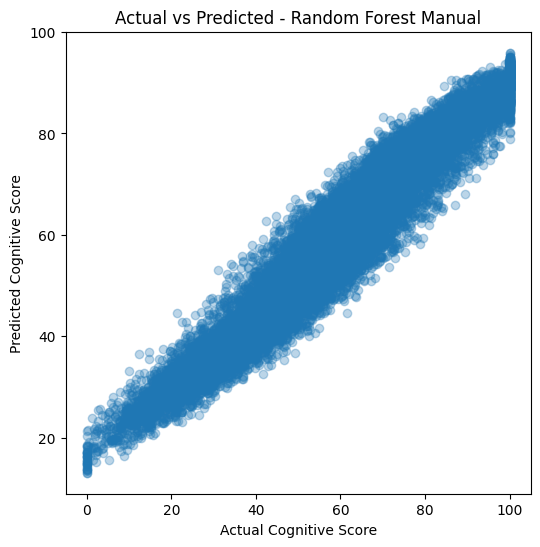

In [52]:

# Visualisasi Actual vs Predicted

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3)
plt.xlabel("Actual Cognitive Score")
plt.ylabel("Predicted Cognitive Score")
plt.title("Actual vs Predicted - Random Forest Manual")
plt.show()

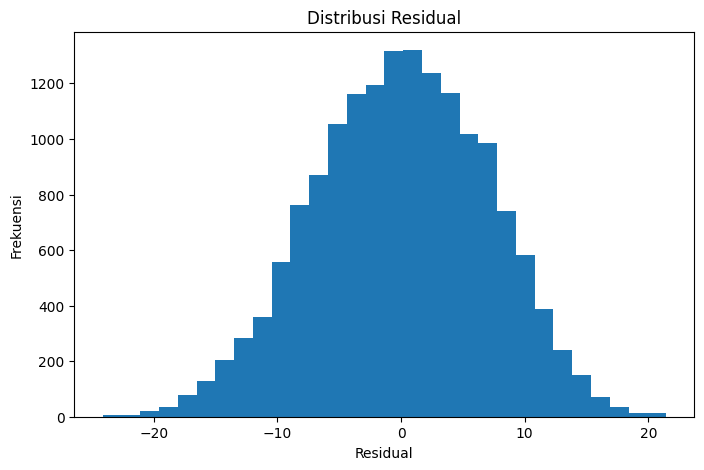

In [53]:
# Visualisasi Error

residuals = y_test - y_pred_best

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30)
plt.xlabel("Residual")
plt.ylabel("Frekuensi")
plt.title("Distribusi Residual")
plt.show()

# **Feature Importance**

In [54]:
# Fungsi Feature Importance

def get_feature_importance(tree, n_features):
    importance = np.zeros(n_features)
    
    def traverse(node):
        if node is None:
            return
        
        if node.feature is not None:
            importance[node.feature] += 1
            traverse(node.left)
            traverse(node.right)
    
    traverse(tree.root)
    return importance

In [55]:
# Hitung Importance dari Semua Tree

n_features = X_train_scaled.shape[1]

total_importance = np.zeros(n_features)

for tree in best_model.trees:
    total_importance += get_feature_importance(tree, n_features)

# normalisasi
total_importance = total_importance / len(best_model.trees)

In [56]:
total_importance

array([11.4 , 28.5 , 31.85, 31.9 , 24.95, 49.9 , 38.1 ,  3.55,  3.3 ,
        3.35,  3.4 , 13.3 ,  9.4 ])

In [57]:
# Mapping ke Nama Fitur

feature_names = X.columns

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": total_importance
})

importance_df = importance_df.sort_values(by="Importance", ascending=False)

importance_df

,Feature,Importance
5,Reaction_Time,49.90
6,Memory_Test_Score,38.10
3,Daily_Screen_Time,31.90
2,Stress_Level,31.85
1,Sleep_Duration,28.50
4,Caffeine_Intake,24.95
11,Exercise_Frequency_Low,13.30
0,Age,11.40
12,Exercise_Frequency_Medium,9.40
7,Gender_Male,3.55


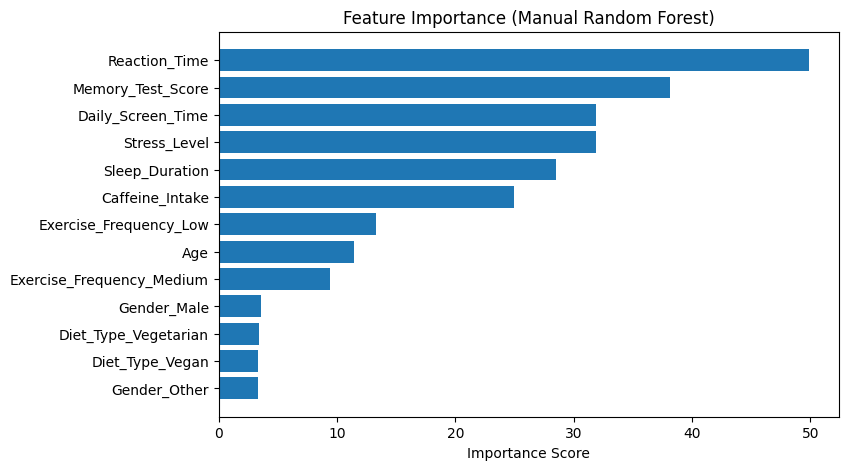

In [58]:
# Visualisasi Feature Importance

plt.figure(figsize=(8,5))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance (Manual Random Forest)")
plt.xlabel("Importance Score")
plt.show()

# **Deployment**

In [59]:
# Save Model

deployment_package = {
    "model": best_model,
    "X_mean": X_mean,
    "X_std": X_std,
    "feature_names": list(X.columns)
}

with open("random_forest_regressor_manual.pkl", "wb") as file:
    pickle.dump(deployment_package, file)

print("Model berhasil disimpan.")

Model berhasil disimpan.


In [60]:
# Load Model

with open("random_forest_regressor_manual.pkl", "rb") as file:
    loaded_package = pickle.load(file)

loaded_model = loaded_package["model"]
loaded_X_mean = loaded_package["X_mean"]
loaded_X_std = loaded_package["X_std"]
loaded_feature_names = loaded_package["feature_names"]

print("Model berhasil dimuat ulang.")

Model berhasil dimuat ulang.


In [61]:
# Contoh Data Baru

new_data = pd.DataFrame([{
    "Age": 25,
    "Sleep_Duration": 7.5,
    "Stress_Level": 4,
    "Daily_Screen_Time": 6,
    "Caffeine_Intake": 120,
    "Reaction_Time": 350,
    "Memory_Test_Score": 80,
    "Gender_Male": 1,
    "Gender_Other": 0,
    "Diet_Type_Vegan": 0,
    "Diet_Type_Vegetarian": 0,
    "Exercise_Frequency_Low": 0,
    "Exercise_Frequency_Medium": 1
}])

new_data = new_data[loaded_feature_names]
new_data

,Age,Sleep_Duration,Stress_Level,Daily_Screen_Time,Caffeine_Intake,Reaction_Time,Memory_Test_Score,Gender_Male,Gender_Other,Diet_Type_Vegan,Diet_Type_Vegetarian,Exercise_Frequency_Low,Exercise_Frequency_Medium
0,25,7.5,4,6,120,350,80,1,0,0,0,0,1


In [62]:
# Scaling Data Baru

new_data_scaled = (new_data.values - loaded_X_mean) / loaded_X_std

new_data_scaled

array([[-1.11849598,  0.28311782, -0.52160491, -0.16189004, -0.89119797,
        -0.43299427,  0.60811473,  1.04439058, -0.2052842 , -0.33017035,
        -0.65670011, -0.81333738,  1.22494423]])

In [63]:
# Prediksi Cognitive Score

prediction = loaded_model.predict(new_data_scaled)

print("Predicted Cognitive Score:", prediction[0])

Predicted Cognitive Score: 82.22931812807361
